In [1]:
%load_ext autoreload
%autoreload 2

import os
import requests
import pandas as pd

from dotenv import load_dotenv
from gasp import baselines, backtest

load_dotenv()
API_KEY = os.getenv("EIA_API_KEY")

In [2]:

#Set up the EIA API request.
url = "https://api.eia.gov/v2/natural-gas/stor/wkly/data/"

params = {
    "api_key": API_KEY,
    "frequency": "weekly",
    "data[0]": "value",
    "facets[series][]": "NW2_EPG0_SWO_R48_BCF",
    "sort[0][column]": "period",
    "sort[0][direction]": "asc",
    "offset": 0,
    "length": 5000
}

#Request the historical storage data from EIA.
response = requests.get(url, params=params, timeout=30)
response.raise_for_status()

#Get the rows returned by the API.
rows = response.json()["response"]["data"]

print("Rows downloaded:", len(rows))

Rows downloaded: 876


In [3]:

#Turn the downloaded data into a DataFrame.
df = pd.DataFrame(rows)[["period", "value"]]

#Convert the dates and storage values into the correct types.
df["period"] = pd.to_datetime(df["period"])
df["value"] = pd.to_numeric(df["value"]).astype(float)

#Add the EIA series ID.
df["series"] = "NW2_EPG0_SWO_R48_BCF"

#Put columns in the correct order and sort from oldest to newest.
df = df[["period", "series", "value"]].sort_values("period").reset_index(drop=True)

#Show the first five rows.
df.head()

,period,series,value
0,2010-01-01,NW2_EPG0_SWO_R48_BCF,3117.0
1,2010-01-08,NW2_EPG0_SWO_R48_BCF,2850.0
2,2010-01-15,NW2_EPG0_SWO_R48_BCF,2607.0
3,2010-01-22,NW2_EPG0_SWO_R48_BCF,2521.0
4,2010-01-29,NW2_EPG0_SWO_R48_BCF,2406.0


In [4]:
#Dummy forecaster that always predicts zero change.
def always_zero(history, target):
    return 0.0

#Test the dummy forecaster from 2021 through 2025.
zero_results = backtest.walk_forward(
    df,
    always_zero,
    "2021-01-01",
    "2025-12-31"
)

#Show the first five predictions.
zero_results.head()


,period,actual,predicted,error
0,2021-01-01,-130.0,0.0,130.0
1,2021-01-08,-134.0,0.0,134.0
2,2021-01-15,-187.0,0.0,187.0
3,2021-01-22,-128.0,0.0,128.0
4,2021-01-29,-192.0,0.0,192.0


In [5]:

#Calculate MAE using our backtest function.
zero_mae = backtest.mae(
    zero_results["actual"],
    zero_results["predicted"]
)

#Calculate the average absolute weekly change.
average_change = zero_results["actual"].abs().mean()

print("Zero forecaster MAE:", zero_mae)
print("Average absolute weekly change:", average_change)

#Both values should be equal.
assert abs(zero_mae - average_change) < 1e-9
print("Sanity check passed!")


Zero forecaster MAE: 78.4521072796935
Average absolute weekly change: 78.4521072796935
Sanity check passed!


In [ ]:

#Checks that the model only receives data from before the target week.
def check_no_leakage(history, target):
    assert history["period"].max() < target #checks that the most recent date the model can see is earlier than the week it's predicting.
    return 0.0

#Run the backtest using the leakage checker.
leakage_results = backtest.walk_forward(
    df,
    check_no_leakage,
    "2021-01-01",
    "2025-12-31"
)

print("No future data leakage detected!")


No future data leakage detected!


In [7]:

#Create a small dataset with only one week of history.
short_history = df.head(1)

#List the three baselines we want to test.
models = [
    baselines.last_change,
    baselines.same_week_last_year,
    baselines.five_year_average
]

#Test each baseline with insufficient history.
for model in models:
    try:
        model(short_history, pd.Timestamp("2021-01-08"))
        print(model.__name__, "FAILED: No error raised")
    except ValueError as e:
        print(model.__name__, "PASSED:", e)


last_change PASSED: Not enough history to calculate last change
same_week_last_year PASSED: Not enough history for same week last year
five_year_average PASSED: Not enough history for five year average


In [8]:
#Store the three baseline forecasting models.
models = {
    "last_change": baselines.last_change,
    "same_week_last_year": baselines.same_week_last_year,
    "five_year_average": baselines.five_year_average
}

results = []
predictions = {}

#Test each model from 2021 through 2025.
for name, model in models.items():
    test = backtest.walk_forward(
        df, model, "2021-01-01", "2025-12-31"
    )

    #Save predictions for the graph later.
    predictions[name] = test

    #Calculate accuracy for each model.
    results.append({
        "model": name,
        "mae": backtest.mae(test["actual"], test["predicted"]),
        "rmse": backtest.rmse(test["actual"], test["predicted"]),
        "bias": backtest.bias(test["actual"], test["predicted"]),
        "n_weeks": len(test),
        "start": test["period"].min(),
        "end": test["period"].max()
    })

#Create the scoreboard, best MAE first.
scoreboard = pd.DataFrame(results).sort_values("mae").reset_index(drop=True)

scoreboard


,model,mae,rmse,bias,n_weeks,start,end
0,five_year_average,31.075096,44.745340,0.817625,261,2021-01-01,2025-12-26
1,last_change,35.306513,53.586289,-0.295019,261,2021-01-01,2025-12-26
2,same_week_last_year,39.352490,56.628148,1.490421,261,2021-01-01,2025-12-26


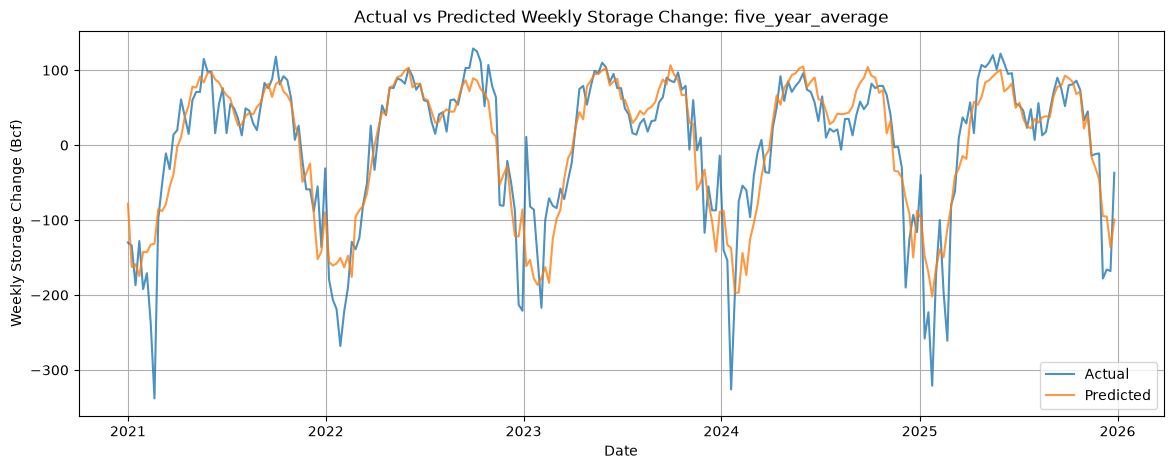

In [9]:

import matplotlib.pyplot as plt

#Get the model with the lowest MAE.
best_model = scoreboard.iloc[0]["model"]

#Get its saved predictions.
best_results = predictions[best_model]

#Create a graph of actual and predicted weekly changes.
plt.figure(figsize=(14, 5))

plt.plot(best_results["period"], best_results["actual"],
         label="Actual", alpha=0.8)

plt.plot(best_results["period"], best_results["predicted"],
         label="Predicted", alpha=0.8)

#Add titles and labels.
plt.title(f"Actual vs Predicted Weekly Storage Change: {best_model}")
plt.xlabel("Date")
plt.ylabel("Weekly Storage Change (Bcf)")
plt.legend()
plt.grid(True)

plt.show()
